# Joint PNN + CDC Equalization: Composite Response and Electronic Filter

This notebook tests whether chromatic dispersion compensation (CDC) can be improved by including the PNN frequency response. All alternatives use the same QPSK frame and linear channel.

**Modeling assumption:** In an ideal coherent receiver, I+jQ is proportional to the optical field. The PNN is therefore applied to the field, and its complex optical output is used before coherent detection. The squared current `|E|²` returned by `forward` is not an input to complex CDC. Noise, Kerr effects, and carrier recovery are outside this study and should be added after the linear case is validated.

The study compares optical and digital compensation strategies in the linear regime.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dsp.transmitter import generate_qpsk_symbols
from src.utils.pnn_model import PhotonicNeuralNetwork
from src.utils.joint_pnn_cdc_equalizer import (
    simulate_fiber_dispersion, cd_compensation_traditional,
    cd_compensation_joint_pnn, calculate_evm_qpsk,
)


## 1. System and Assumptions

The PNN delay is chosen as an integer multiple of the sampling period, avoiding wrap-around from FFT interpolation in the fractional-delay model. Fixed deterministic weights make the experiment reproducible. Inverse regularization is swept relative to the mean power of `H_PNN`, since an absolute value such as `1e-3` depends on weight normalization.

In [2]:
NUM_SYMBOLS = 2**13
SPS = 8
SYMBOL_RATE = 10e9
FS = SPS * SYMBOL_RATE
DT = 1 / FS
LENGTH_KM = 40.0
DISPERSION_D = 16.0
WAVELENGTH = 1550e-9
SEED = 42

# Δt = 25 ps corresponds to two samples at Fs = 80 GSa/s.
PNN = PhotonicNeuralNetwork(
    num_channels=8, base_delay_ps=25.0,
    amplitude_weights=np.array([1.00, .90, .78, .68, .58, .48, .38, .28]),
    phase_weights=np.array([0.0, .18, -.12, .27, -.22, .16, -.10, .08]),
    normalize_power=True,
)

symbols, bits = generate_qpsk_symbols(NUM_SYMBOLS, seed=SEED)
# Rectangular NRZ pulse: 8 samples per symbol. This test focuses on inversion of the
# channel/PNN; an RRC pulse response can be added in a future study.
tx = np.repeat(symbols, SPS).astype(complex)
# Guard interval to reduce delay and circular-FFT edge effects.
guard = 4 * PNN.num_channels * SPS
tx = np.pad(tx, (guard, guard))
print(f'{NUM_SYMBOLS} symbols | Fs={FS/1e9:.1f} GSa/s | Δt={PNN.base_delay_ps:.1f} ps | guard={guard} samples')


8192 symbols | Fs=80.0 GSa/s | Δt=25.0 ps | guard=256 samples


## 2. Composite Response and Inverses

In the linear model, `H_total(f) = H_fibra(f) H_PNN(f)`. Conventional CDC removes only the fiber dispersion phase and leaves `H_PNN` in the signal. The joint equalizer applies `H_fibra⁻¹` and a Wiener/Tikhonov inverse of the PNN. We also inspect `H_PNN` magnitude, since zeros or deep notches make inversion sensitive to noise.

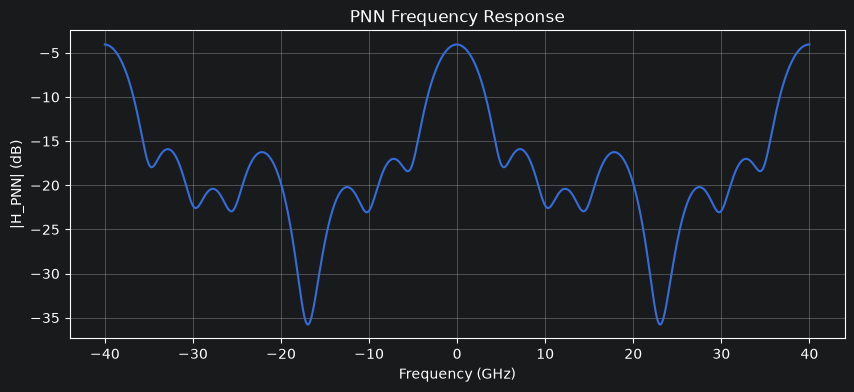

|H_PNN|: minimum=0.0163, maximum=0.627; ε=5.74e-05


In [3]:
freq = np.fft.fftfreq(len(tx), d=DT)
h_pnn = PNN.frequency_response(freq)
regularization_rel = 1e-3
epsilon = regularization_rel * np.mean(np.abs(h_pnn)**2)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.fft.fftshift(freq)/1e9, 20*np.log10(np.maximum(np.abs(np.fft.fftshift(h_pnn)), 1e-12)))
ax.set(xlabel='Frequency (GHz)', ylabel='|H_PNN| (dB)', title='PNN Frequency Response')
ax.grid(True); plt.show()
print(f'|H_PNN|: minimum={np.min(np.abs(h_pnn)):.3g}, maximum={np.max(np.abs(h_pnn)):.3g}; ε={epsilon:.3g}')


## 3. Transmission Chain and Compared Conditions

The conditions are: no PNN/no CDC; CDC alone; PNN alone; PNN followed by conventional CDC; and PNN followed by the joint equalizer. The last two use exactly the same PNN output. The joint equalizer uses the same regularization at every frequency.

In [4]:
# Field after the fiber and PNN: forward also returns the field before square-law detection.
field_fiber = simulate_fiber_dispersion(
    tx, DT, LENGTH_KM, dispersion_d=DISPERSION_D, wavelength=WAVELENGTH
)
_, field_pnn = PNN.forward(field_fiber, DT, return_optical_field=True)

rx = {
    'TX (reference)': tx.copy(),
    'CDC only': cd_compensation_traditional(
        field_fiber, DT, LENGTH_KM, dispersion_d=DISPERSION_D, wavelength=WAVELENGTH
    ),
    'PNN only': field_pnn.copy(),
    'PNN + conventional CDC': cd_compensation_traditional(
        field_pnn, DT, LENGTH_KM, dispersion_d=DISPERSION_D, wavelength=WAVELENGTH
    ),
    'PNN + joint CDC': cd_compensation_joint_pnn(
        field_pnn, DT, LENGTH_KM, PNN, dispersion_d=DISPERSION_D,
        wavelength=WAVELENGTH, reg_factor=epsilon
    ),
}


## 4. Alignment, EVM, and BER

For each output, the best integer shift within ±1 symbol is selected, and one complex gain is fitted using only the useful region. The same symbol reference is used to calculate EVM and BER. This gain/phase correction does not undo ISI; it only avoids penalizing trivial scale and phase differences.

In [5]:
def evaluate_waveform(waveform, max_offset=SPS):
    best = None
    # Discard guards and fit one complex scalar on the evaluation frame.
    ref = symbols
    for offset in range(-max_offset, max_offset + 1):
        sample_idx = guard + SPS//2 + np.arange(NUM_SYMBOLS)*SPS + offset
        valid = (sample_idx >= 0) & (sample_idx < len(waveform))
        idx = sample_idx[valid]
        target = ref[valid]
        y = waveform[idx]
        gain = np.vdot(y, target) / max(np.vdot(y, y).real, 1e-30)
        aligned = gain * y
        evm = np.sqrt(np.mean(np.abs(aligned-target)**2) / np.mean(np.abs(target)**2))*100
        dec = (aligned.real >= 0).astype(int)
        decq = (aligned.imag >= 0).astype(int)
        b_hat = np.empty(2*len(aligned), dtype=int)
        b_hat[0::2] = dec; b_hat[1::2] = decq
        b_ref = bits[:len(b_hat)]
        ber = np.mean(b_hat != b_ref)
        if best is None or evm < best['EVM RMS (%)']:
            best = {'EVM RMS (%)': evm, 'BER': ber, 'offset (samples)': offset, 'gain': gain}
    return best

rows = []
for name, waveform in rx.items():
    result = evaluate_waveform(waveform)
    rows.append({'Condition': name, **{k:v for k,v in result.items() if k != 'gain'}})
results = pd.DataFrame(rows).set_index('Condition')
display(results.style.format({'EVM RMS (%)':'{:.3f}', 'BER':'{:.3e}'}))


,EVM RMS (%),BER,offset (samples)
Condition,,,
TX (reference),0.000,1.000e+00,-4
CDC only,0.000,1.000e+00,-4
PNN only,43.922,1.000e+00,5
PNN + conventional CDC,45.619,1.000e+00,3
PNN + joint CDC,1.030,1.000e+00,1


## 5. Regularization Sensitivity

### Why is a regularization parameter needed?

The joint equalizer attempts to undo both the PNN response and fiber dispersion. After removing the fiber phase, the regularized PNN inverse is computed frequency by frequency as

\[H_{\mathrm{PNN,inv}}(f)=\frac{H_{\mathrm{PNN}}^*(f)}{|H_{\mathrm{PNN}}(f)|^2+\varepsilon}.\]

For very small \(\varepsilon\), this approaches \(1/H_{\mathrm{PNN}}(f)\). It better restores frequencies attenuated by the PNN, but may require large gain near deep notches in \(|H_{\mathrm{PNN}}(f)|\). In a noisy system, that gain also amplifies noise. Increasing \(\varepsilon\) limits amplification and stabilizes inversion, at the cost of leaving part of the PNN response uncompensated.

### What the sweep does

The following cell keeps the received signal after the fiber and PNN, PNN weights, and channel parameters fixed. It varies only \(\varepsilon\): nine logarithmically spaced values from \(10^{-6}\) to \(10^{-1}\), scaled by the mean of \(|H_{\mathrm{PNN}}|^2\). This makes the tested values relative to the PNN response power. For each value, the code reapplies the joint equalizer and measures RMS EVM and BER using the same timing alignment and complex-gain fit described above.

### What to look for

The curve shows residual distortion for each regularization trade-off. With very small regularization, a closer inversion is expected in the noiseless linear model, provided there are no exact PNN zeros and boundary effects are controlled. As \(\varepsilon\) increases, inversion becomes more conservative; EVM may rise, followed by BER if errors cross QPSK decision boundaries. A flat region suggests low sensitivity to the precise choice of \(\varepsilon\); a sharp change suggests sensitivity and warrants inspection of PNN spectral notches.

This initial experiment **does not include ASE or AWGN**. It therefore does not directly measure the benefit of regularization against noise amplification: with noiseless data, reducing \(\varepsilon\) may appear beneficial until numerical limits, spectral zeros, or boundary distortions arise. To choose \(\varepsilon\) for a realistic receiver, repeat the sweep with known noise levels and compare output quality (ideally SNR or EVM) against OSNR. Regularization is applied to the PNN inverse; the inverse of the ideal fiber phase response has unit magnitude and needs no such protection in this model.

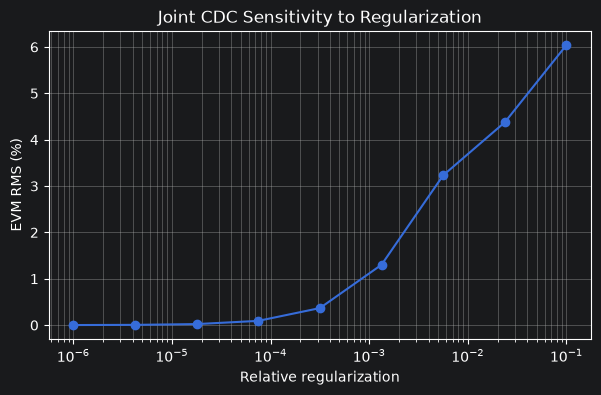

,ε / mean(|H_PNN|²),EVM RMS (%),BER
0,1.0e-06,0.001,1.000e+00
1,4.2e-06,0.005,1.000e+00
2,1.8e-05,0.022,1.000e+00
3,7.5e-05,0.091,1.000e+00
4,3.2e-04,0.367,1.000e+00
5,1.3e-03,1.301,1.000e+00
6,5.6e-03,3.230,1.000e+00
7,2.4e-02,4.375,1.000e+00
8,1.0e-01,6.041,1.000e+00


In [7]:
reg_grid = np.logspace(-6, -1, 9)
reg_rows = []
for reg_rel in reg_grid:
    y = cd_compensation_joint_pnn(
        field_pnn, DT, LENGTH_KM, PNN, dispersion_d=DISPERSION_D,
        wavelength=WAVELENGTH, reg_factor=reg_rel*np.mean(np.abs(h_pnn)**2)
    )
    m = evaluate_waveform(y)
    reg_rows.append((reg_rel, m['EVM RMS (%)'], m['BER']))
reg_df = pd.DataFrame(reg_rows, columns=['ε / mean(|H_PNN|²)','EVM RMS (%)','BER'])
fig, ax = plt.subplots(figsize=(7,4))
ax.semilogx(reg_df.iloc[:,0], reg_df['EVM RMS (%)'], marker='o')
ax.set(xlabel='Relative regularization', ylabel='EVM RMS (%)', title='Joint CDC Sensitivity to Regularization')
ax.grid(True, which='both'); plt.show()
display(reg_df.style.format({'ε / mean(|H_PNN|²)':'{:.1e}','EVM RMS (%)':'{:.3f}','BER':'{:.3e}'}))


## 6. Interpretation and Limitations

- The main comparison is `PNN + conventional CDC` versus `PNN + joint CDC`; the expected advantage in the linear case depends on whether `H_PNN` is invertible and well-conditioned.
- The joint equalizer uses `reg_factor` as an additive ε term in |H|². The default absolute value `1e-3` is not universal; different weight scales change the result.
- The repository PNN class normalizes weights by `N`, as does the joint module. This differs from the `1/√N` normalization described elsewhere in the PNN documentation. Using the same implementation for applying and inverting the PNN keeps this comparison consistent, but power results require a clearly stated convention.
- Block FFT inversion assumes periodicity. Guard intervals and edge cropping reduce, but do not eliminate, boundary artifacts.
- The PNN performs a linear optical sum followed by square-law detection. The presented joint equalizer can invert only the linear field response observed by the coherent receiver; it cannot invert a `|E|²` current using a complex filter.
- Next steps: add ASE noise, sweep PNN delay and weights, and test carrier phase/frequency offsets; then evaluate nonlinear propagation and compatible equalizers on an independent test set.

## References

The supplied papers on transversal equalization and integrated equalizers provide context for the digital equalizer discussion. This notebook does not directly reproduce the published results.